En este apartado estudiamos en que idioma realizaron los estudiantes la prueba en la comunidad valenciana, y si coincide con su idioma materno o no. 

En el Pais Vasco, los cuales solo entre 2022 y 2025 perdieron 47 puntos en la competencia lectora, realizaron este mismo estudio. Pudieron ver que entre los estudiantes que hablan español en casa, la proporción que hicieron PISA en euskera aumentó del 11% en 2022 al 56% en 2025, tras moverse entre un 1% y un 13% desde 2003. En una sola ronda, alrededor del 40% de todos los estudiantes vascos cambiaron la lengua de su examen, bajando al mismo tiempo la competencia lectora unos 47 puntos. 

Este estudio se realiza para explorar de la misma manera, si un posible cambio en el idioma de hacer la prueba puede estar relacionado con la bajada en la competencia lectora en Valencia 2025

In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns
import funcionalidades as fn

In [2]:
# Leemos los csv creados en mainpisa y guardados en la carpeta datos
df_valencia25=pd.read_csv('data/pisa_valencia25.csv')
df_valencia22=pd.read_csv('data/pisa_valencia22.csv')
df_valencia18=pd.read_csv('data/pisa_valencia18.csv')

In [ ]:


p_esp_val25 = fn.pct_idioma(df_valencia25, 156, "val")    # 156: español, "val" = Valencian en 2025
p_esp_val22 = fn.pct_idioma(df_valencia22, 156, [608, 160])      # 156: español, 608 = Valencian en 2022
p_esp_val18 = fn.pct_idioma(df_valencia18, 156, [608, 160]) 
print("--------PORCETAJES PONDERADOS CASTELLANOPARLANTES PRUEBA VALENCIANO--------")
print(f"En 2025:  {round(p_esp_val25, 1)}")
print(f"En 2022:  {round(p_esp_val22, 1)}")
print(f"En 2018:  {round(p_esp_val18, 1)}")

p_esp_esp25 = fn.pct_idioma(df_valencia25, 156, "esp")    # 156: español, "val" = Valencian en 2025
p_esp_esp22 = fn.pct_idioma(df_valencia22, 156, 156)      # 156: español, 608 = Valencian en 2022
p_esp_esp18 = fn.pct_idioma(df_valencia18, 156, 156) 
print("--------PORCETAJES PONDERADOS CASTELLANOPARLANTES PRUEBA CASTELLANO--------")
print(f"En 2025:  {round(p_esp_esp25, 1)}")
print(f"En 2022:  {round(p_esp_esp22, 1)}")
print(f"En 2018:  {round(p_esp_esp18, 1)}")

p_val_val25 = fn.pct_idioma(df_valencia25, 160, "val")    # 160:cat, "val" = Valencian en 2025
p_val_val22 = fn.pct_idioma(df_valencia22, [160, 608], 608)      # val:608, 608 = Valencian en 2022
p_val_val18 = fn.pct_idioma(df_valencia18, [160, 608], 608) 
print("--------PORCETAJES PONDERADOS VALENCIANOPARLANTES PRUEBA VALENCIANO--------")
print(f"En 2025:  {round(p_val_val25, 1)}")
print(f"En 2022:  {round(p_val_val22, 1)}")
print(f"En 2018:  {round(p_val_val18, 1)}")

p_val_esp25 = fn.pct_idioma(df_valencia25, 160, "esp")    # 160:cat, "val" = Valencian en 2025
p_val_esp22 = fn.pct_idioma(df_valencia22, [160, 608], 156)      # val:608, 608 = Valencian en 2022
p_val_esp18 = fn.pct_idioma(df_valencia18, [160, 608], 156) 
print("--------PORCETAJES PONDERADOS VALENCIANOPARLANTES PRUEBA CASTELLANO--------")
print(f"En 2025:  {round(p_val_esp25, 1)}")
print(f"En 2022:  {round(p_val_esp22, 1)}")
print(f"En 2018:  {round(p_val_esp18, 1)}")

p_other_x25 = fn.pct_idioma(df_valencia25, [690.0,474.0,451], ["esp","val"])    # 160:cat, "val" = Valencian en 2025
p_other_x22 = fn.pct_idioma(df_valencia22, [999,852,474,668,451], [608,160,156])      # val:608, 608 = Valencian en 2022
p_other_x18 = fn.pct_idioma(df_valencia18, [999,852,451], [608,156,160]) 
print("--------PORCETAJES PONDERADOS OTHER LANG --------")
print(f"En 2025:  {round(p_other_x25, 1)}")
print(f"En 2022:  {round(p_other_x22, 1)}")
print(f"En 2018:  {round(p_other_x18, 1)}")


--------PORCETAJES PONDERADOS CASTELLANOPARLANTES PRUEBA VALENCIANO--------
En 2025:  12.2
En 2022:  0.7
En 2018:  11.5
--------PORCETAJES PONDERADOS CASTELLANOPARLANTES PRUEBA CASTELLANO--------
En 2025:  61.8
En 2022:  70.8
En 2018:  56.2
--------PORCETAJES PONDERADOS VALENCIANOPARLANTES PRUEBA VALENCIANO--------
En 2025:  7.8
En 2022:  3.5
En 2018:  10.5
--------PORCETAJES PONDERADOS VALENCIANOPARLANTES PRUEBA CASTELLANO--------
En 2025:  3.7
En 2022:  13.3
En 2018:  12.5
--------PORCETAJES PONDERADOS OTHER LANG --------
En 2025:  14.4
En 2022:  11.3
En 2018:  9.0


In [4]:
# Comprobamos que la suma de porcentajes por año da 100
suma25=p_val_val25+p_esp_val25+p_esp_esp25+p_other_x25+p_val_esp25
print(suma25)
suma22=p_val_val22+p_esp_val22+p_esp_esp22+p_other_x22+p_val_esp22
print(suma22)
suma18=p_val_val18+p_esp_val18+p_esp_esp18+p_other_x18+p_val_esp18
print(suma18)

100.0
99.56775612614855
99.75755925352254


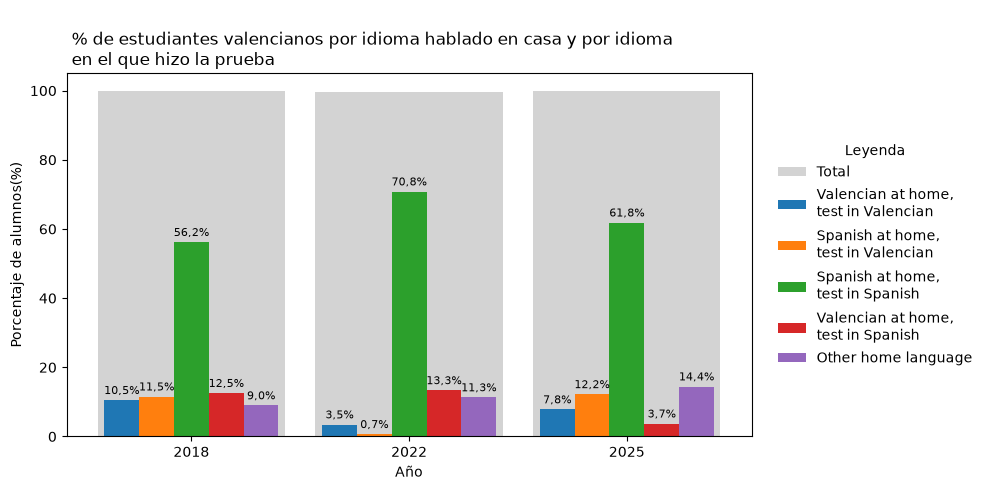

In [5]:
# -------REPRESENTACIÓN DE RESULTADOS----------

data = pd.DataFrame(
    {
        "value": [
            # --- 2018 ---
            p_val_val18,
            p_esp_val18,
            p_esp_esp18,
            p_val_esp18,
            p_other_x18,
            # --- 2022 ---
            p_val_val22,
            p_esp_val22,
            p_esp_esp22,
            p_val_esp22,
            p_other_x22,
            # --- 2025 ---
            p_val_val25,
            p_esp_val25,
            p_esp_esp25,
            p_val_esp25,
            p_other_x25,
            ],
        "category": [
            "2018",
            "2018",
            "2018",
            "2018",
            "2018",
            "2022",
            "2022",
            "2022",
            "2022",
            "2022",
            "2025",
            "2025",
            "2025",
            "2025",
            "2025",
        ],
        "sub_category": [
            'Valencian at home,\ntest in Valencian',
            'Spanish at home,\ntest in Valencian',
            'Spanish at home,\ntest in Spanish',
            'Valencian at home,\ntest in Spanish',
            'Other home language',
            'Valencian at home,\ntest in Valencian',
            'Spanish at home,\ntest in Valencian',
            'Spanish at home,\ntest in Spanish',
            'Valencian at home,\ntest in Spanish',
            'Other home language',
            'Valencian at home,\ntest in Valencian',
            'Spanish at home,\ntest in Valencian',
            'Spanish at home,\ntest in Spanish',
            'Valencian at home,\ntest in Spanish',
            'Other home language',
        ],
    }
)

cat_order = ["2018", "2022", "2025"]
data["category"] = pd.Categorical(data["category"], categories=cat_order, ordered=True)
data = data.sort_values(["category", "value"], ascending=[True, False])


pivot_df = data.pivot(index="category", columns="sub_category", values="value")

# CAMBIO 1: orden fijo de las subcategorías (pivot las ordena alfabéticamente)
orden = ['Valencian at home,\ntest in Valencian',
         'Spanish at home,\ntest in Valencian',
         'Spanish at home,\ntest in Spanish',
         'Valencian at home,\ntest in Spanish',
         'Other home language']
pivot_df = pivot_df[orden]
totals = pivot_df.sum(axis=1)

fig, ax = plt.subplots(figsize=(10, 5))          # un poco más ancha para dejar sitio a la leyenda

# CAMBIO 2: el ancho de cada barra se calcula a partir del nº de subcategorías
n = len(pivot_df.columns)                        # 5
ancho_grupo = 0.8                                # ancho total de cada año (menos de 1 para que no se toquen)
bar_width = ancho_grupo / n
x = np.arange(len(pivot_df.index))

# CAMBIO 3: el fondo gris es un poco más ancho que el grupo de barras
ax.bar(x, totals, width=ancho_grupo + 0.06, color="lightgrey", zorder=0, label="Total")

umbral = 8     # barras con menos de este % llevan la etiqueta encima

for i, sub_cat in enumerate(pivot_df.columns):
    # CAMBIO 4: desplazamiento centrado: (i - (n-1)/2)
    barras= ax.bar(
        x + (i - (n - 1) / 2) * bar_width,
        pivot_df[sub_cat],
        width=bar_width,
        label=sub_cat,
        zorder=1,
    )
    # NUEVO: escribimos el % de cada barra
    for barra, v in zip(barras, pivot_df[sub_cat]):
        texto = f"{v:.1f}%".replace(".", ",")
        cx = barra.get_x() + barra.get_width() / 2
        ax.text(cx, v + 1, texto, ha="center", va="bottom",
                fontsize=8, color="black", zorder=2)

ax.set_xlabel("Año")
ax.set_ylabel("Porcentaje de alumnos(%)")
ax.set_title(f" \n % de estudiantes valencianos por idioma hablado en casa y por idioma \n en el que hizo la prueba ", loc="left")
ax.set_xticks(x)
ax.set_xticklabels(pivot_df.index)

# CAMBIO 5: leyenda fuera del gráfico, a la derecha
ax.legend(title="Leyenda", loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)

fig.tight_layout()
plt.savefig("imgs/grafico_idioma.png", dpi=200, bbox_inches="tight")
plt.show()

- Observaciones

Entre el alumnado que habla español en casa, la proporción evaluada en valenciano era de ≈12% en 2018, ≈1% en 2022 y ≈12% en 2025.
Sumando las dos barras de valenciano, el alumnado evaluado en ese idioma pasa de ≈22,0% (2018) a ≈4,5% (2022) y ≈20,0% (2025). 
Por tanto, 2022 es el año atípico, con muy poco valenciano, y 2018 y 2025 tienen una distribución de idioma de prueba casi idéntica.

Con estos datos, el idioma de la prueba no parece un factor principal de la caída de 2025. Como mucho pudo contribuir en una parte pequeña del tramo 2022→2025, y no explica la diferencia con 2018. Las explicaciones principales habría que seguir buscándolas en otros factores.

In [13]:

# pd.crosstab cuenta cuántos alumnos hay en cada combinación de idioma en casa e idioma de la prueba, 
# y margins=True añade los totales.
por_centro = df_valencia25.groupby("CNTSCHID").agg(
    alumnos=("CNTSTUID", "size"),
    pct_val=("LANGTEST_COG", lambda s: (s == "val").mean() * 100),
    estrato=("STRATUM", "first"),
)

# Clasificamos cada centro según el idioma en que examinó a su alumnado
por_centro["tipo"] = pd.cut(por_centro["pct_val"], bins=[-1, 0, 99.999, 100],
                            labels=["Solo español", "Mixto", "Solo valenciano"])

print("Cuántos centros hay de cada tipo: ")
print(por_centro["tipo"].value_counts(), "\n" )   
print(" División por público/privado según el tipo de centro: ")                  
print(pd.crosstab(por_centro["estrato"], por_centro["tipo"]), "\n") 
print("Cuántos alumnos hay en cada tipo de centro") 
print(por_centro.groupby("tipo")["alumnos"].sum())           

Cuántos centros hay de cada tipo: 
tipo
Solo español       40
Mixto               8
Solo valenciano     6
Name: count, dtype: int64 

 División por público/privado según el tipo de centro: 
tipo     Solo español  Mixto  Solo valenciano
estrato                                      
ESP33              21      8                6
ESP34              19      0                0 

Cuántos alumnos hay en cada tipo de centro
tipo
Solo español       1246
Mixto               274
Solo valenciano     192
Name: alumnos, dtype: int64
